# Execution Algorithm Research — SET50 (hourly)

**คำถามวิจัย:** ถ้าใช้ *parent order ชุดเดียวกัน* algo แต่ละตัว (MARKET, TWAP, VWAP, POV) เสียต้นทุน execution ต่างกันเท่าไหร่ และผลนี้ขึ้นกับขนาด order, ช่วงเวลาของวัน และ volatility แค่ไหน

**สมมติฐานที่ทดสอบ**
1. **H1** order ยิ่งใหญ่เมื่อเทียบกับ ADV algo ที่ทยอยส่ง (TWAP, VWAP, POV) จะยิ่งถูกกว่า MARKET เพราะ impact เพิ่มตาม √ขนาด
2. **H2** VWAP ถูกกว่า TWAP เพราะส่งหนักในชั่วโมงที่ตลาดซื้อขายมาก ทำให้ participation ต่อแท่งต่ำกว่า
3. **H3** algo ที่ทยอยส่งแลกต้นทุนที่ต่ำลงด้วย *ความเสี่ยง* ที่สูงขึ้น (std ของ IS สูงขึ้นจาก timing risk)

ทุกค่าที่ปรับได้อยู่ใน `src/constants.py` ส่วนการทดลองทั้งหมดรันผ่าน `src/experiment.run_experiment()` ตัวเดียวกับ `run.py`

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from src import constants as C, plots
from src.experiment import run_experiment

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plots.style()
ex = run_experiment()                      # ~15 s: main run + sensitivity + in-sample check
mk, summ = ex["market"], ex["summary"]

## 1. ข้อมูลและการเตรียมข้อมูล

* ไฟล์ `SET50_2023–2026.csv` แท่งรายชั่วโมง มี OHLC, `TRADING_VALUE` (บาท) และ `TRADING_VOLUME` (หุ้น) ครบ 50 หุ้น
* เก็บเฉพาะแท่ง **10, 11, 12, 13, 15, 16, 17** ได้ 7 แท่งต่อวันเท่ากันทุกวัน ส่วนแท่ง 14:00 ตัดทิ้ง (หายไปราว 30% ของวัน และไม่มีเลยทั้งปี 2023) แถวแปลกๆ ที่ 00/01/09 ก็ตัดทิ้ง
* **Bar VWAP** = value ÷ volume แล้ว clip ให้อยู่ในช่วง [low, high] ของแท่ง ใช้เป็นราคา fill
* **ราคาไม่ได้ปรับ corporate action** (เช่น BANPU +172% ในชั่วโมงเดียว) จึงตัด order ที่ช่วง execution มีแท่งไหน |return| เกิน 15%
* **Point-in-time universe:** แต่ละวันเลือก Top 10 ตามมูลค่าซื้อขายเฉลี่ย 20 วัน *ก่อนหน้า* (ไม่ใช้ข้อมูลของวันนั้น จึงไม่มี look-ahead)
* **In-sample** (2023–24) ใช้สร้าง volume profile ของ VWAP เท่านั้น ส่วน **out-of-sample** (2025–26) ใช้สุ่มและ execute parent order

,data
files,"[SET50_2023.csv, SET50_2024.csv, SET50_2025.cs..."
rows_raw,343633
rows_off_grid,30832
bars,6576
tickers,50
start,2023-01-03 10:00:00
end,2026-11-19 17:00:00
jump_bars,10
vwap_clipped_share,0.00


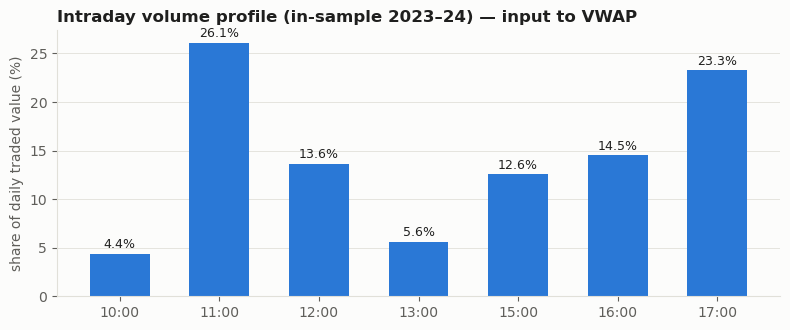

datetime,10,11,12,13,15,16,17
share of daily value (%),4.35,26.08,13.63,5.63,12.55,14.50,23.25


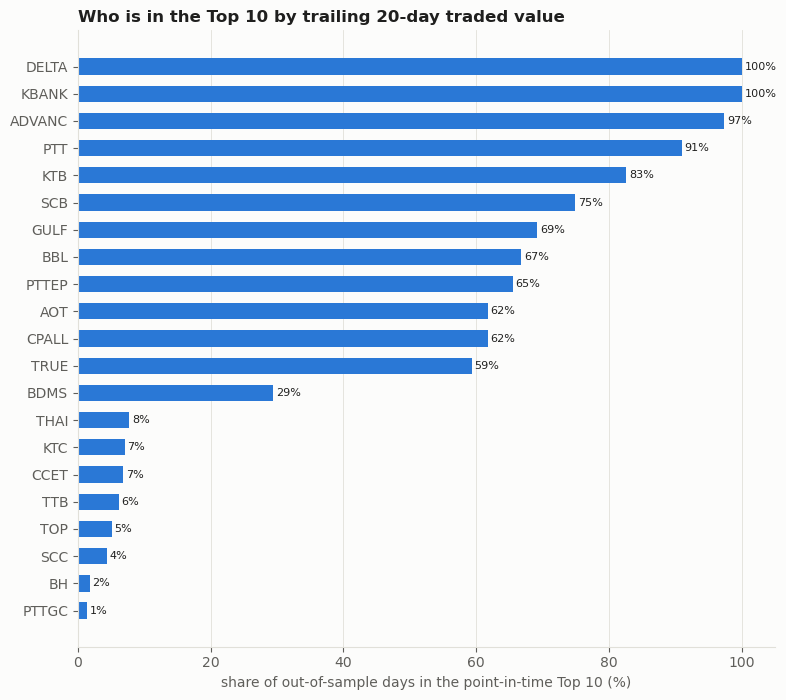

In [2]:
display(pd.Series({k: v for k, v in mk.info.items()}, name="data").to_frame())
plots.volume_profile(mk.profile); plt.show()
display((mk.profile * 100).rename("share of daily value (%)").to_frame().T)
plots.universe_frequency(mk.top, "2025-01-01"); plt.show()

## 2. Market model และ cost model

ทุก child order fill ที่ **VWAP ของแท่งที่ fill** และจ่ายต้นทุนดังนี้

| ส่วน | สูตร | หมายเหตุ |
|---|---|---|
| ½ spread | `SPREAD_TICKS × tick(price) / 2` | **ค่าสมมติ** 1 tick เพราะไม่มี bid/ask (sensitivity ที่ 2 tick) |
| impact | `Y × σ_hour × √(child ÷ มูลค่าซื้อขายของแท่ง) × price` | square-root law, Y = 1 (sensitivity 0.5, 2), σ ex-ante 100 แท่ง ไม่รวม jump |
| commission | 0.157% × (1 + VAT 7%) | |

กติกาการ fill
* ตัดสินใจและตั้ง arrival ที่ Close_t แล้ว child แรกเริ่มที่แท่ง t+1
* แท่งที่ไม่มีการซื้อขาย (value = 0) fill ไม่ได้
* impact เป็นแบบ **ชั่วคราว** ไม่สะสมข้ามแท่ง (ข้อจำกัด: ไม่มี permanent impact)

## 3. ออกแบบการทดลอง — parent order

1. สุ่ม **2,000 ชุด** ของ (แท่งที่ตัดสินใจ, หุ้น, ฝั่งซื้อ/ขาย) ในช่วง out-of-sample
   * หุ้นสุ่มจาก Top 10 ของวันนั้น
   * แท่งต้องมีเวลาเหลือครบ horizon 7 แท่ง
2. แต่ละชุดใช้ **ทั้ง 4 ขนาด** คือ 1%, 5%, 10% และ 25% ของ NAV 100M (1M, 5M, 10M, 25M บาท) ได้ทั้งหมด **8,000 order** ผลของ "ขนาด" จึงวัดบนเวลา หุ้น และฝั่งเดียวกันทุกประการ
3. **ทุก algo execute order ชุดเดียวกัน** การเทียบระหว่าง algo จึงเป็นแบบ paired
4. ฝั่งขายถือว่ามีหุ้นอยู่แล้ว ไม่มีข้อจำกัดเรื่องพอร์ตหรือเงินสด เพราะงานนี้ศึกษาเฉพาะ execution

In [3]:
od = ex["orders"]
print(ex["orders_info"])
display(od.groupby("bucket", sort=False).agg(n=("order_id", "size"), notional_M=("paper_notional", lambda s: s.mean() / 1e6),
        pct_adv_median=("pct_adv", lambda s: s.median() * 100), pct_adv_p95=("pct_adv", lambda s: s.quantile(.95) * 100))
        .sort_values("notional_M"))
display(od.drop_duplicates("base_id").groupby("ticker").size().sort_values(ascending=False).rename("draws").to_frame().T)

{'period': 'out', 'n_base': 2000, 'n_orders': 8000, 'rejected_draws': {'jump': 0, 'no_price': 0, 'no_sigma': 0}, 'first_decision_allowed': '2025-01-02 10:00:00', 'last_decision_allowed': '2026-11-18 17:00:00'}


,n,notional_M,pct_adv_median,pct_adv_p95
bucket,,,,
1% NAV,2000,0.99,0.05,0.10
5% NAV,2000,4.99,0.27,0.51
10% NAV,2000,9.99,0.54,1.01
25% NAV,2000,24.99,1.34,2.53


ticker,KBANK,DELTA,ADVANC,PTT,PTTEP,KTB,SCB,GULF,BBL,AOT,CPALL,TRUE,BDMS,THAI,TOP,KTC,SCC,CCET,TTB,PTTGC,BH
draws,222,202,194,154,151,149,144,136,131,128,127,119,57,19,17,13,12,10,10,3,2


## 4. Algorithm ทั้ง 4 ตัว (horizon = 7 แท่ง = 1 วันเทรด, เริ่มที่ t+1)

| Algo | ต้องการส่งเท่าไหร่ในแท่ง t+1+k | cap ต่อแท่ง | ถ้าไม่เสร็จ |
|---|---|---|---|
| **MARKET** | ที่เหลือทั้งหมด (แท่งแรกที่มีการซื้อขาย) | ไม่มี cap จ่าย impact เต็ม | — |
| **TWAP** | เป้าสะสม Q·(k+1)/7 − ที่ fill ไปแล้ว | 25% ของมูลค่าในแท่ง | ส่วนที่ขาดตามเก็บในแท่งถัดไป ครบ horizon แล้ว cancel |
| **VWAP** | เป้าสะสม Q·Σprofile(ชั่วโมงถึง k) ÷ Σprofile − ที่ fill ไปแล้ว | 25% ของมูลค่าในแท่ง | เหมือน TWAP |
| **POV** | 10% × มูลค่าซื้อขาย *จริง* ของแท่ง | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |

ส่วนที่ cancel คิดเป็น **opportunity cost** ที่ Close_{t+7}

กราฟข้างล่างเป็นตัวอย่าง order ขนาด 25% NAV หนึ่งตัว ที่ทั้ง 4 algo execute

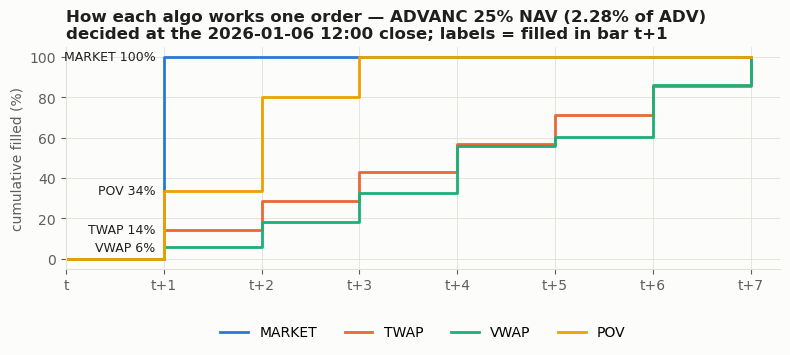

,algo,datetime,qty,bar_vwap,bar_value,participation,impact,exec_price
60580,MARKET,2026-01-06 13:00:00,77300,322.04,"83,858,200.00",0.30,0.75,323.29
60581,TWAP,2026-01-06 13:00:00,11000,322.04,"83,858,200.00",0.04,0.28,322.82
60582,TWAP,2026-01-06 15:00:00,11000,321.32,"116,156,200.00",0.03,0.24,322.06
60583,TWAP,2026-01-06 16:00:00,11100,319.52,"455,823,800.00",0.01,0.12,320.14
60584,TWAP,2026-01-06 17:00:00,11000,320.68,"289,509,500.00",0.01,0.15,321.33
60585,TWAP,2026-01-07 10:00:00,11100,320.31,"56,406,000.00",0.06,0.35,321.15
60586,TWAP,2026-01-07 11:00:00,11000,319.78,"335,768,400.00",0.01,0.14,320.42
60587,TWAP,2026-01-07 12:00:00,11100,318.97,"208,383,800.00",0.02,0.18,319.65
60588,VWAP,2026-01-06 13:00:00,4300,322.04,"83,858,200.00",0.02,0.18,322.71
60589,VWAP,2026-01-06 15:00:00,9700,321.32,"116,156,200.00",0.03,0.23,322.04


In [4]:
res, fills = ex["results"], ex["fills"]
pick = od[(od.bucket == "25% NAV")].sort_values("pct_adv").iloc[int(len(od) / 4 * 0.9)]
plots.example_schedule(fills, pick); plt.show()
display(fills[fills.order_id == pick.order_id][["algo", "datetime", "qty", "bar_vwap", "bar_value", "participation", "impact", "exec_price"]])

## 5–6. Simulation engine, benchmark และ metric

* `src/engine.py` ทำงานทีละแท่ง โดยทุก algo ใช้เส้นทาง fill และ cost เดียวกัน ต่างกันแค่จำนวนที่อยากส่งในแต่ละแท่ง
* **Implementation Shortfall (IS)** เทียบกับ paper trade Q × arrival (ค่าบวก = ต้นทุน) แยกเป็น:
  * **timing:** ราคาเคลื่อนระหว่างตอนตัดสินใจถึงตอน fill
  * **spread:** ½ spread ที่จ่ายทุก fill
  * **impact:** ราคาที่ขยับเพราะ order ของเราเอง
  * **commission:** ค่าคอมมิชชั่นรวม VAT
  * **opportunity:** ต้นทุนของส่วนที่ fill ไม่ทัน
* **vs interval VWAP:** ราคา fill เฉลี่ยเทียบกับ VWAP ของตลาดช่วง t+1 … t+7
* ตัวเลขทั้งหมดเป็น bps และ `is_std` คือ std ของ IS ต่อ order ใช้เป็นตัววัดความเสี่ยง

In [5]:
cols = ["bucket", "algo", "pct_adv_mean", "is_mean", "is_ci_lo", "is_ci_hi", "is_median", "is_std",
        "timing_mean", "spread_mean", "impact_mean", "commission_mean", "opportunity_mean",
        "vs_ivwap_mean", "fully_filled_share", "bars_used_mean", "max_participation_p95"]
t = summ[cols].copy(); t["pct_adv_mean"] *= 100
display(t)

,bucket,algo,pct_adv_mean,is_mean,is_ci_lo,is_ci_hi,is_median,is_std,timing_mean,spread_mean,impact_mean,commission_mean,opportunity_mean,vs_ivwap_mean,fully_filled_share,bars_used_mean,max_participation_p95
0,1% NAV,MARKET,0.06,47.72,44.73,50.92,44.18,74.40,0.45,23.42,7.06,16.79,0.00,28.45,1.00,1.01,0.05
1,1% NAV,TWAP,0.06,44.62,38.92,49.81,40.32,128.60,1.70,23.45,2.67,16.77,0.04,25.48,1.00,6.99,0.02
2,1% NAV,VWAP,0.06,44.33,38.72,49.55,38.94,127.22,1.83,23.45,2.25,16.77,0.03,25.19,1.00,6.99,0.01
3,1% NAV,POV,0.06,47.51,44.49,50.78,44.14,74.31,0.50,23.42,6.80,16.79,0.00,28.24,1.00,1.03,0.05
4,5% NAV,MARKET,0.29,56.48,53.39,59.73,51.83,75.81,0.45,23.42,15.83,16.79,0.00,37.22,1.00,1.01,0.25
5,5% NAV,TWAP,0.29,47.88,42.17,53.06,43.06,128.14,1.68,23.44,5.95,16.77,0.04,28.75,1.00,6.99,0.11
6,5% NAV,VWAP,0.29,47.10,41.52,52.29,41.84,126.70,1.82,23.45,5.03,16.77,0.03,27.96,1.00,6.99,0.05
7,5% NAV,POV,0.29,53.46,50.38,56.68,49.27,75.23,0.47,23.42,12.77,16.79,0.00,34.18,1.00,1.20,0.10
8,10% NAV,MARKET,0.57,63.04,59.90,66.36,58.39,77.53,0.45,23.42,22.39,16.79,0.00,43.79,1.00,1.01,0.50
9,10% NAV,TWAP,0.57,50.24,44.61,55.43,45.28,128.10,1.65,23.44,8.34,16.76,0.05,31.13,0.99,6.99,0.22


## 7. ผลลัพธ์
### 7.1 ต้นทุนตามขนาด order (เส้น = ค่าเฉลี่ย, แถบสี = bootstrap 95% CI)

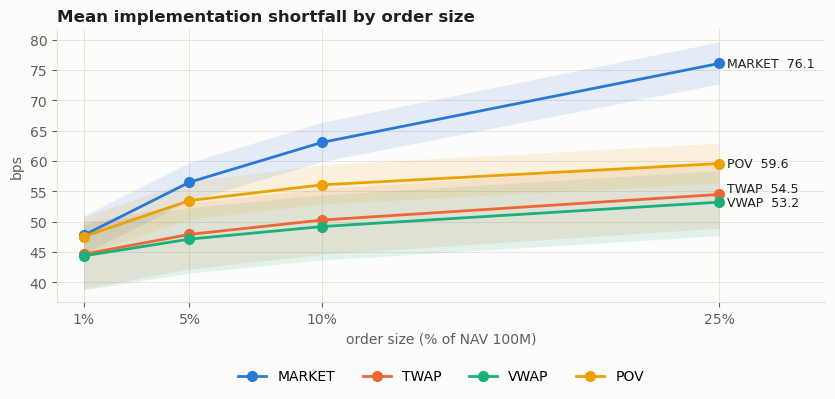

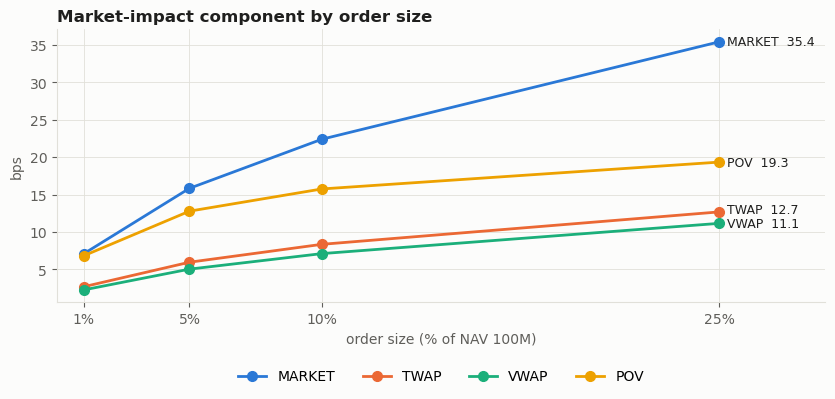

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,7.06,15.83,22.39,35.40
TWAP,2.67,5.95,8.34,12.67
VWAP,2.25,5.03,7.10,11.14
POV,6.80,12.77,15.74,19.33


In [6]:
plots.is_by_size(summ); plt.show()
plots.is_by_size(summ, col="impact_mean", title="Market-impact component by order size", ci=False); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="impact_mean")[sorted(summ.bucket.unique(), key=lambda b: float(b.split('%')[0]))])

### 7.2 Cost–risk frontier
ยิ่งต่ำยิ่งถูก ยิ่งไปซ้ายยิ่งเสี่ยงน้อย ไม่มี algo ตัวไหนชนะทั้งสองแกนพร้อมกัน

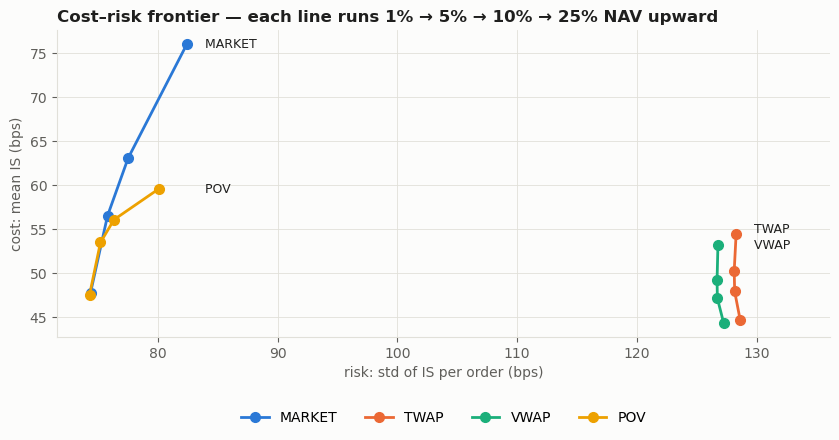

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,74.40,75.81,77.53,82.45
TWAP,128.60,128.14,128.10,128.27
VWAP,127.22,126.70,126.67,126.75
POV,74.31,75.23,76.35,80.09


In [7]:
plots.frontier(summ); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="is_std")[sorted(summ.bucket.unique(), key=lambda b: float(b.split('%')[0]))])

### 7.3 แยกตามชั่วโมงที่ตัดสินใจ และระดับ volatility (order 25% NAV)

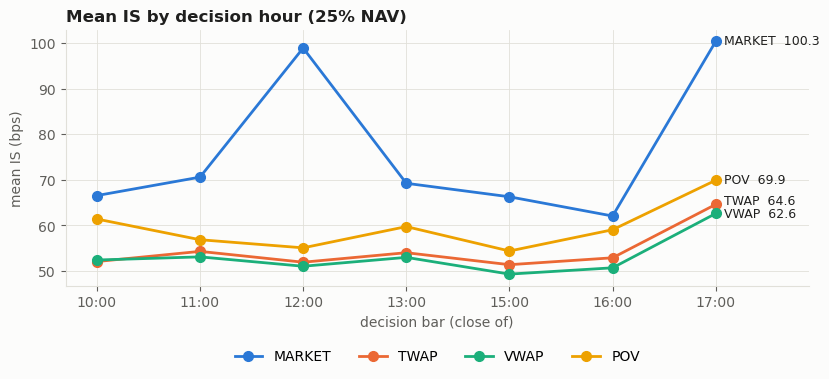

algo,MARKET,TWAP,VWAP,POV
hour,,,,
10,66.55,52.10,52.43,61.41
11,70.59,54.32,53.12,56.88
12,98.88,51.95,51.07,55.10
13,69.24,54.03,53.01,59.75
15,66.28,51.41,49.35,54.40
16,62.07,52.92,50.72,59.06
17,100.34,64.62,62.63,69.92


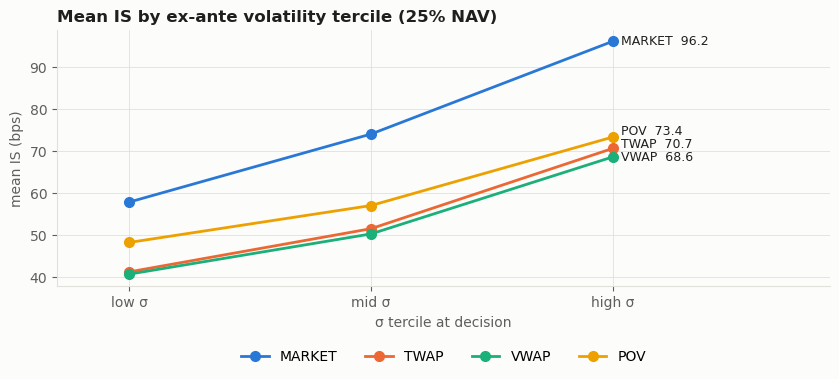

algo                 MARKET  TWAP  VWAP   POV
bucket  vol_tercile                          
1% NAV  low σ         40.27 35.11 35.20 40.15
        mid σ         48.43 42.43 42.12 48.28
        high σ        54.47 56.31 55.68 54.10
5% NAV  low σ         45.71 37.08 36.92 43.93
        mid σ         56.36 45.43 44.67 53.25
        high σ        67.37 61.13 59.71 63.19
10% NAV low σ         49.79 38.55 38.19 45.87
        mid σ         62.30 47.60 46.58 54.95
        high σ        77.03 64.57 62.75 67.32
25% NAV low σ         57.88 41.23 40.68 48.24
        mid σ         74.09 51.52 50.27 57.04
        high σ        96.20 70.65 68.63 73.36

In [8]:
bh, bv = ex["by_hour"], ex["by_vol"]
plots.by_group(bh, "hour", "25% NAV", "Mean IS by decision hour (25% NAV)", "decision bar (close of)"); plt.show()
display(bh[bh.bucket == "25% NAV"].set_index("hour").drop(columns="bucket"))
plots.by_group(bv, "vol_tercile", "25% NAV", "Mean IS by ex-ante volatility tercile (25% NAV)", "σ tercile at decision"); plt.show()
display(bv.set_index(["bucket", "vol_tercile"]))

## 8. การทดสอบทางสถิติ (paired บน order_id)

`mean_diff` = IS ของ a − IS ของ b (ค่าติดลบ = a ถูกกว่า) มี bootstrap 95% CI ประกอบ
* `t_p_holm` คือ paired t-test ที่ปรับด้วย Holm (6 คู่ต่อ bucket)
* `wilcoxon_p` คือ signed-rank test ซึ่งไม่ต้องสมมติว่าข้อมูลกระจายแบบปกติ
* `share_a_cheaper` คือสัดส่วนของ order ที่ a ถูกกว่า b

In [9]:
display(ex["paired"])

,bucket,a,b,n,mean_diff,ci_lo,ci_hi,share_a_cheaper,t_p,wilcoxon_p,t_p_holm,significant
0,1% NAV,MARKET,TWAP,2000,3.10,-1.27,7.45,0.47,0.17,0.03,0.62,False
1,1% NAV,MARKET,VWAP,2000,3.39,-0.96,7.69,0.47,0.12,0.01,0.62,False
2,1% NAV,MARKET,POV,2000,0.21,0.08,0.39,0.00,0.01,0.00,0.06,False
3,1% NAV,TWAP,VWAP,2000,0.29,-0.29,0.88,0.49,0.34,0.07,0.62,False
4,1% NAV,TWAP,POV,2000,-2.89,-7.24,1.48,0.53,0.20,0.04,0.62,False
5,1% NAV,VWAP,POV,2000,-3.18,-7.47,1.18,0.53,0.15,0.02,0.62,False
6,5% NAV,MARKET,TWAP,2000,8.60,4.23,12.96,0.43,0.00,0.00,0.00,True
7,5% NAV,MARKET,VWAP,2000,9.38,5.07,13.75,0.44,0.00,0.00,0.00,True
8,5% NAV,MARKET,POV,2000,3.02,2.40,3.73,0.03,0.00,0.00,0.00,True
9,5% NAV,TWAP,VWAP,2000,0.78,0.21,1.37,0.46,0.01,0.00,0.02,True


## 9. Sensitivity และ robustness

ปรับทีละพารามิเตอร์ ตัวอื่นคงไว้ที่ค่าหลัก แล้วรันซ้ำบน order 8,000 ตัวเดิม

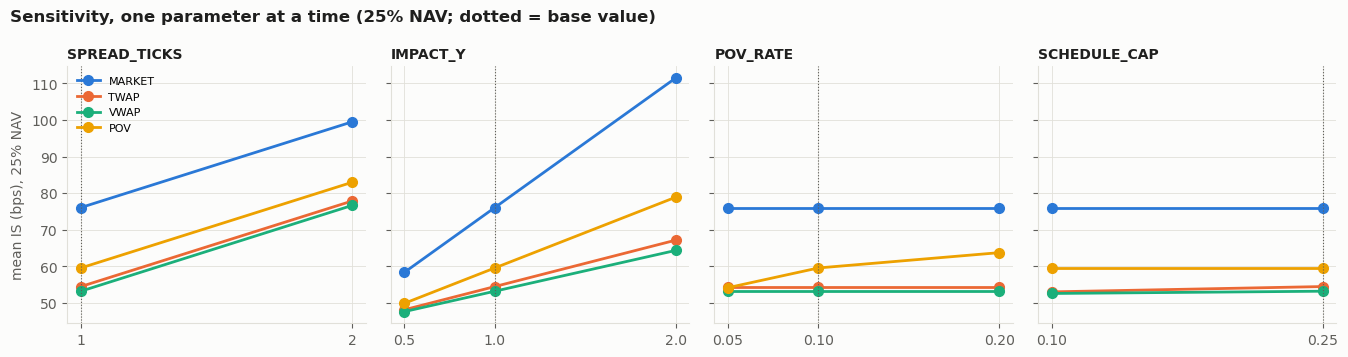

bucket             1% NAV 5% NAV 10% NAV 25% NAV
param        value                              
IMPACT_Y     0.50    VWAP   VWAP    VWAP    VWAP
             1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP
POV_RATE     0.05    VWAP   VWAP    VWAP    VWAP
             0.10    VWAP   VWAP    VWAP    VWAP
             0.20    VWAP   VWAP    VWAP    VWAP
SCHEDULE_CAP 0.10    VWAP   VWAP    VWAP    VWAP
             0.25    VWAP   VWAP    VWAP    VWAP
SPREAD_TICKS 1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP

In [10]:
sens = ex["sensitivity"]
plots.sensitivity(sens, "25% NAV"); plt.show()
win = sens[sens["rank"] == 1].pivot_table(index=["param", "value"], columns="bucket", values="algo", aggfunc="first")
display(win[sorted(win.columns, key=lambda b: float(b.split('%')[0]))])

**In-sample check:** สุ่ม order ชุดใหม่ในช่วง 2023–24 ซึ่ง VWAP profile ถูก calibrate บนช่วงเดียวกันนี้ ถ้า VWAP ดูดีแค่ใน in-sample แปลว่า overfit

In [11]:
si = ex["summary_in"].set_index(["bucket", "algo"])[["is_mean", "is_std"]]
so = summ.set_index(["bucket", "algo"])[["is_mean", "is_std"]]
cmp_ = si.join(so, lsuffix="_in", rsuffix="_out")
display(cmp_.reindex(so.index))

is_mean_in  is_std_in  is_mean_out  is_std_out
bucket  algo                                                  
1% NAV  MARKET       48.50      59.65        47.72       74.40
        TWAP         44.36      98.05        44.62      128.60
        VWAP         43.96      96.64        44.33      127.22
        POV          48.15      59.58        47.51       74.31
5% NAV  MARKET       57.29      60.88        56.48       75.81
        TWAP         47.70      97.85        47.88      128.14
        VWAP         46.77      96.31        47.10      126.70
        POV          53.29      60.17        53.46       75.23
10% NAV MARKET       63.87      62.38        63.04       77.53
        TWAP         50.10      97.95        50.24      128.10
        VWAP         48.87      96.36        49.17      126.67
        POV          55.51      61.27        56.04       76.35
25% NAV MARKET       76.93      66.62        76.06       82.45
        TWAP         54.28      98.29        54.47      128.27
        VWAP         52.86      96.58        53.19      126.75
        POV          58.42      65.24        59.55       80.09

## 10. สรุปและข้อจำกัด

ตัวเลขทั้งหมดมาจากการรันด้วย seed ใน `constants.py` (8,000 order, out-of-sample 2025-01 → 2026-11) รันซ้ำได้ผลเดิมทุกครั้ง

### ข้อค้นพบ
1. **มีต้นทุนพื้นฐานราว 40 bps ที่ algo ไหนก็เลี่ยงไม่ได้** มาจาก ½ spread (≈ 23 bps ภายใต้ค่าสมมติ 1 tick) กับ commission + VAT (≈ 17 bps) algo ต่างกันแค่ส่วน **impact** กับ **timing**
2. **H1 ยืนยัน:** order ยิ่งใหญ่ MARKET ยิ่งแพงกว่าตัวอื่น
   * ที่ 1% NAV (≈ 0.06% ของ ADV) ทุก algo อยู่ในช่วง 44–48 bps และ paired t-test หลังปรับ Holm **ไม่มีนัยสำคัญ**
   * ตั้งแต่ 5% NAV (≈ 0.3% ของ ADV) ขึ้นไป TWAP, VWAP และ POV ถูกกว่า MARKET **อย่างมีนัยสำคัญ**
   * ที่ 25% NAV (≈ 1.4% ของ ADV) MARKET อยู่ที่ 76.1 bps ส่วน VWAP อยู่ที่ 53.2 bps ต่างกัน **22.9 bps** (95% CI 18.4–27.5) หรือประมาณ 57,000 บาทต่อ order ขนาด 25M
3. **H2 ยืนยัน แต่ส่วนต่างเล็ก:** VWAP ถูกกว่า TWAP 0.8–1.3 bps อย่างมีนัยสำคัญตั้งแต่ 5% NAV ขึ้นไป ส่วนต่างทั้งหมดมาจาก impact ที่ต่ำกว่า เพราะ VWAP ส่งหนักในชั่วโมงที่ตลาดซื้อขายมาก (11:00 และ 17:00) participation ต่อแท่งจึงต่ำกว่า
4. **H3 ยืนยัน:** ต้นทุนที่ต่ำลงแลกมาด้วยความเสี่ยงที่สูงขึ้น
   * std ของ IS ต่อ order ของ TWAP/VWAP อยู่ราว 127 bps ส่วน MARKET อยู่ที่ 74–82 และ POV ที่ 74–80
   * สาเหตุคือการทยอยส่งตลอดทั้งวันทำให้ราคาที่ fill ขึ้นกับว่าราคาเคลื่อนไปทางไหนระหว่างวัน
   * POV 10% เป็นทางสายกลาง: ความเสี่ยงใกล้ MARKET แต่ถูกกว่า 3–17 bps ตั้งแต่ 5% NAV ขึ้นไป (ที่ 1% NAV แทบไม่ต่างกัน)
5. **ช่วงเวลาของวันมีผลมากกับ MARKET:**
   * order 25% ที่ตัดสินใจตอนปิดแท่ง 12:00 หรือ 17:00 ใช้ MARKET แล้วแพงถึงราว 99–100 bps เพราะแท่งถัดไปบางมาก คือแท่ง 13:00 (ช่วงพักเที่ยง ≈ 5.6% ของมูลค่าทั้งวัน) และแท่ง 10:00 ของเช้าวันถัดไปซึ่งเป็น auction (≈ 4.4%)
   * TWAP และ VWAP แทบไม่ได้รับผลนี้
   * order ที่เริ่มหลังปิดแท่ง 17:00 ของทุก algo แพงขึ้นเล็กน้อย อาจมาจาก overnight gap แต่ด้วยจำนวน order ต่อชั่วโมง (~285 ตัว) ความต่างนี้ยังไม่แน่นอนทางสถิติ
6. **Volatility:** σ ยิ่งสูง ต้นทุนของทุก algo ยิ่งสูง MARKET ไวต่อ σ มากที่สุด (25% NAV: 58 → 96 bps) อันดับของ algo ไม่เปลี่ยน ยกเว้น order เล็ก (1% NAV) ในช่วง σ สูง ที่ MARKET และ POV ถูกกว่า TWAP/VWAP เล็กน้อย เพราะเมื่อ impact แทบไม่มี การทยอยส่งไม่ได้ช่วยอะไร มีแต่เพิ่ม timing risk
7. **Robustness:**
   * VWAP เป็นอันดับ 1 ใน **ทุก** ค่าของ sensitivity (spread, impact Y, POV rate, cap) และทุกขนาด order
   * spread 2 tick เพิ่มต้นทุนให้ทุก algo ราว 23 bps เท่าๆ กัน ส่วน impact Y = 2 ทำให้ช่องว่างระหว่าง MARKET กับตัวอื่นกว้างขึ้นมาก
   * ผล in-sample (2023–24) แทบเท่ากับ out-of-sample จึงไม่มีสัญญาณว่า volume profile ของ VWAP overfit

### ข้อเสนอเชิงปฏิบัติ (ภายใต้สมมติฐานของแบบจำลองนี้)
* **order ≤ ~0.1% ของ ADV:** algo ไหนก็ได้ ส่วนต่างไม่มีนัยสำคัญ ถ้าต้องการลด timing risk ใช้ MARKET หรือ POV
* **order ≥ ~0.3% ของ ADV และรับ timing risk ทั้งวันได้:** ใช้ **VWAP** (หรือ TWAP ซึ่งแพงกว่าเล็กน้อย)
* **ต้องการความแน่นอนของราคา:** ใช้ **POV 10%** แลกต้นทุนที่สูงกว่า VWAP ราว 6 bps เพื่อลด std ลงราว 35–40%
* **หลีกเลี่ยง MARKET order ก้อนใหญ่ก่อนพักเที่ยงและหลังปิดตลาด**

### ข้อจำกัด
* **ไม่มี bid/ask และไม่มี order book:** spread เป็นค่าสมมติ ซึ่งเป็นตัวกำหนดระดับต้นทุนส่วนใหญ่ (แต่ไม่เปลี่ยนอันดับของ algo)
* **แท่งรายชั่วโมง:** สมมติว่า child ได้ราคาเท่า VWAP ของแท่งพอดี ซึ่งจริงๆ อาจดีหรือแย่กว่านี้ก็ได้ ส่วน MARKET ก็สมมติให้ fill ที่ VWAP ของแท่ง t+1 แทนที่จะ fill ทันทีที่ Close_t
* **Impact model ไม่ได้ calibrate จาก order จริงของเรา:** ใช้ square-root law กับ Y = 1 เป็นแบบชั่วคราวเท่านั้น ไม่มี permanent impact และไม่มีการรั่วไหลของข้อมูล
* **Look-ahead เล็กน้อย:** cap และ POV ใช้มูลค่าซื้อขายของแท่งที่กำลัง fill ซึ่งรู้ได้หลังแท่งจบเท่านั้น
* **ราคาไม่ได้ปรับ corporate action:** แก้ด้วยการตัด order ที่ช่วง execution มีราคากระโดด แต่ไม่ได้ปรับราคา
* **ขอบเขตการทดลอง:** ฝั่งขายสมมติว่ามีหุ้นอยู่แล้ว, horizon เดียว (1 วัน) และ universe เฉพาะ Top 10 ซึ่งเป็นหุ้นสภาพคล่องสูง ผลกับหุ้นที่คล่องตัวน้อยอาจต่างออกไป